Kết nối Google Drive với Colab

In [101]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Kiểm tra dữ liệu

In [102]:
import os

folder = "/content/drive/MyDrive/Fakeddit"

print("Các file trong thư mục Fakeddit:")

for file in os.listdir(folder):
    print(file)

Các file trong thư mục Fakeddit:
multimodal_test_public.tsv
multimodal_train.tsv
multimodal_validate.tsv
multimodal_only_samples


Đọc thử dữ liệu

In [103]:
import pandas as pd

folder = "/content/drive/MyDrive/Fakeddit"

train = pd.read_csv(
    folder + "/multimodal_train.tsv",
    sep="\t"
)

print("Kích thước dữ liệu:", train.shape)
print("Tên các cột:")
print(train.columns.tolist())

display(train.head())

Kích thước dữ liệu: (564000, 16)
Tên các cột:
['author', 'clean_title', 'created_utc', 'domain', 'hasImage', 'id', 'image_url', 'linked_submission_id', 'num_comments', 'score', 'subreddit', 'title', 'upvote_ratio', '2_way_label', '3_way_label', '6_way_label']


,author,clean_title,created_utc,domain,hasImage,id,image_url,linked_submission_id,num_comments,score,subreddit,title,upvote_ratio,2_way_label,3_way_label,6_way_label
0,Alexithymia,my walgreens offbrand mucinex was engraved wit...,1.551641e+09,i.imgur.com,True,awxhir,https://external-preview.redd.it/WylDbZrnbvZdB...,NaN,2.0,12,mildlyinteresting,My Walgreens offbrand Mucinex was engraved wit...,0.84,1,0,0
1,VIDCAs17,this concerned sink with a tiny hat,1.534727e+09,i.redd.it,True,98pbid,https://preview.redd.it/wsfx0gp0f5h11.jpg?widt...,NaN,2.0,119,pareidolia,This concerned sink with a tiny hat,0.99,0,2,2
2,prometheus1123,hackers leak emails from uae ambassador to us,1.496511e+09,aljazeera.com,True,6f2cy5,https://external-preview.redd.it/6fNhdbc6K1vFA...,NaN,1.0,44,neutralnews,Hackers leak emails from UAE ambassador to US,0.92,1,0,0
3,NaN,puppy taking in the view,1.471341e+09,i.imgur.com,True,4xypkv,https://external-preview.redd.it/HLtVNhTR6wtYt...,NaN,26.0,250,photoshopbattles,PsBattle: Puppy taking in the view,0.95,1,0,0
4,3rikR3ith,i found a face in my sheet music too,1.525318e+09,i.redd.it,True,8gnet9,https://preview.redd.it/ri7ut2wn8kv01.jpg?widt...,NaN,2.0,13,pareidolia,I found a face in my sheet music too!,0.84,0,2,2


Kiểm tra dữ liệu

In [104]:
# Kiểm tra dữ liệu bị thiếu
print("Số lượng dữ liệu bị thiếu:")
print(train.isnull().sum())

# Kiểm tra số lượng nhãn
print("\nPhân bố nhãn:")
print(train["2_way_label"].value_counts())

# Kiểm tra 5 mẫu dữ liệu
display(train.head())

Số lượng dữ liệu bị thiếu:
author                   28710
clean_title                  0
created_utc                  0
domain                  167857
hasImage                     0
id                           0
image_url                 1534
linked_submission_id    396143
num_comments            167857
score                        0
subreddit                    0
title                        0
upvote_ratio            167857
2_way_label                  0
3_way_label                  0
6_way_label                  0
dtype: int64

Phân bố nhãn:
2_way_label
0    341919
1    222081
Name: count, dtype: int64


,author,clean_title,created_utc,domain,hasImage,id,image_url,linked_submission_id,num_comments,score,subreddit,title,upvote_ratio,2_way_label,3_way_label,6_way_label
0,Alexithymia,my walgreens offbrand mucinex was engraved wit...,1.551641e+09,i.imgur.com,True,awxhir,https://external-preview.redd.it/WylDbZrnbvZdB...,NaN,2.0,12,mildlyinteresting,My Walgreens offbrand Mucinex was engraved wit...,0.84,1,0,0
1,VIDCAs17,this concerned sink with a tiny hat,1.534727e+09,i.redd.it,True,98pbid,https://preview.redd.it/wsfx0gp0f5h11.jpg?widt...,NaN,2.0,119,pareidolia,This concerned sink with a tiny hat,0.99,0,2,2
2,prometheus1123,hackers leak emails from uae ambassador to us,1.496511e+09,aljazeera.com,True,6f2cy5,https://external-preview.redd.it/6fNhdbc6K1vFA...,NaN,1.0,44,neutralnews,Hackers leak emails from UAE ambassador to US,0.92,1,0,0
3,NaN,puppy taking in the view,1.471341e+09,i.imgur.com,True,4xypkv,https://external-preview.redd.it/HLtVNhTR6wtYt...,NaN,26.0,250,photoshopbattles,PsBattle: Puppy taking in the view,0.95,1,0,0
4,3rikR3ith,i found a face in my sheet music too,1.525318e+09,i.redd.it,True,8gnet9,https://preview.redd.it/ri7ut2wn8kv01.jpg?widt...,NaN,2.0,13,pareidolia,I found a face in my sheet music too!,0.84,0,2,2


Kiểm tra các cột dữ liệu

In [105]:
print("Danh sách cột:")
for col in train.columns:
    print("-", col)

Danh sách cột:
- author
- clean_title
- created_utc
- domain
- hasImage
- id
- image_url
- linked_submission_id
- num_comments
- score
- subreddit
- title
- upvote_ratio
- 2_way_label
- 3_way_label
- 6_way_label


Tiền xử lý văn bản

In [106]:
train["title"] = train["title"].fillna("")

# Sử dụng trực tiếp cột 'title' thay vì kết hợp với 'selftext' không tồn tại
train["text"] = train["title"].astype(str)

print("Dữ liệu văn bản sau xử lý:")
display(train[["text", "2_way_label"]].head())

Dữ liệu văn bản sau xử lý:


,text,2_way_label
0,My Walgreens offbrand Mucinex was engraved wit...,1
1,This concerned sink with a tiny hat,0
2,Hackers leak emails from UAE ambassador to US,1
3,PsBattle: Puppy taking in the view,1
4,I found a face in my sheet music too!,0


Kiểm tra hình ảnh

In [107]:
if "image" in train.columns:
    print("Có cột hình ảnh!")
    print(train["image"].head())

else:
    print("Chưa tìm thấy cột image.")

Chưa tìm thấy cột image.


Giai đoạn 2: Tiền xử lý dữ liệu

Chuẩn hóa văn bản

In [108]:
import re

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\S+", "", text)
    text = re.sub(r"[^a-zA-Z0-9\s]", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

train["text"] = train["text"].apply(clean_text)

print("Văn bản sau khi chuẩn hóa:")
display(train[["text", "2_way_label"]].head())

Văn bản sau khi chuẩn hóa:


,text,2_way_label
0,my walgreens offbrand mucinex was engraved wit...,1
1,this concerned sink with a tiny hat,0
2,hackers leak emails from uae ambassador to us,1
3,psbattle puppy taking in the view,1
4,i found a face in my sheet music too,0


Kiểm tra và loại bỏ dữ liệu không hợp lệ

In [109]:
train = train.dropna(subset=["2_way_label"])

train["2_way_label"] = pd.to_numeric(
    train["2_way_label"],
    errors="coerce"
)

train = train.dropna(subset=["2_way_label"])

train["2_way_label"] = train["2_way_label"].astype(int)

train = train[train["2_way_label"].isin([0, 1])]

train = train[train["text"].str.strip() != ""]

print("Số mẫu còn lại:", len(train))
print(train["2_way_label"].value_counts())

Số mẫu còn lại: 562323
2_way_label
0    340243
1    222080
Name: count, dtype: int64


Chuyển văn bản thành dữ liệu số bằng TF-IDF

In [110]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(
    max_features=10000,
    stop_words="english"
)

X = vectorizer.fit_transform(train["text"])

y = train["2_way_label"]

print("Kích thước dữ liệu:", X.shape)

Kích thước dữ liệu: (562323, 10000)


Chia dữ liệu huấn luyện và kiểm tra

In [111]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Dữ liệu huấn luyện:", X_train.shape)
print("Dữ liệu kiểm tra:", X_test.shape)

Dữ liệu huấn luyện: (449858, 10000)
Dữ liệu kiểm tra: (112465, 10000)


Giai đoạn 3: Xây dựng mô hình

Huấn luyện mô hình phát hiện tin giả

In [112]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced"
)

model.fit(X_train, y_train)

print("Huấn luyện mô hình thành công!")

Huấn luyện mô hình thành công!


Dự đoán kết quả

In [113]:
y_pred = model.predict(X_test)

print("Kết quả dự đoán:")
print(y_pred[:20])

Kết quả dự đoán:
[0 1 0 0 0 1 1 0 0 0 1 0 1 0 0 0 0 0 1 0]


Tính các chỉ số đánh giá

In [114]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

print("Accuracy:", accuracy_score(y_test, y_pred))

print("Precision:",
      precision_score(y_test, y_pred, zero_division=0))

print("Recall:",
      recall_score(y_test, y_pred, zero_division=0))

print("F1-score:",
      f1_score(y_test, y_pred, zero_division=0))

print("\nBáo cáo phân loại:")
print(classification_report(y_test, y_pred))

Accuracy: 0.8465567065309207
Precision: 0.7880491271238572
Recall: 0.8364328170028819
F1-score: 0.8115204403717822

Báo cáo phân loại:
              precision    recall  f1-score   support

           0       0.89      0.85      0.87     68049
           1       0.79      0.84      0.81     44416

    accuracy                           0.85    112465
   macro avg       0.84      0.84      0.84    112465
weighted avg       0.85      0.85      0.85    112465



Vẽ ma trận nhầm lẫn

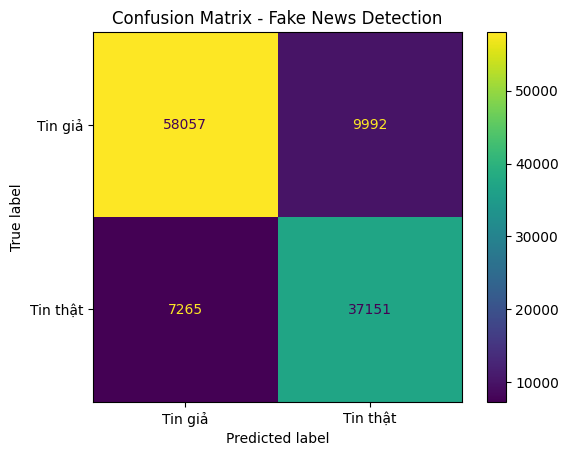

In [115]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Tin giả", "Tin thật"]
)

plt.title("Confusion Matrix - Fake News Detection")
plt.show()

Giai đoạn 5: Xây dựng mô hình đa phương thức

Cài đặt thư viện xử lý hình ảnh

In [116]:
!pip install -q torch torchvision pillow

Import thư viện

In [117]:
import torch
import torch.nn as nn
import torchvision.models as models

from torchvision import transforms
from PIL import Image
import numpy as np
import os

Kiểm tra cột hình ảnh

In [118]:
print(train.columns.tolist())

['author', 'clean_title', 'created_utc', 'domain', 'hasImage', 'id', 'image_url', 'linked_submission_id', 'num_comments', 'score', 'subreddit', 'title', 'upvote_ratio', '2_way_label', '3_way_label', '6_way_label', 'text']


Kiểm tra dữ liệu ảnh

In [119]:
if "image" in train.columns:
    print(train["image"].head(10))
else:
    print("Không tìm thấy cột image!")

Không tìm thấy cột image!


Khởi tạo mô hình MobileNetV2

In [120]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

weights = models.MobileNet_V2_Weights.DEFAULT

image_model = models.mobilenet_v2(weights=weights)

image_model.classifier = nn.Identity()

image_model = image_model.to(device)
image_model.eval()

print("Thiết bị:", device)
print("Đã khởi tạo MobileNetV2!")

Thiết bị: cpu
Đã khởi tạo MobileNetV2!


Chuẩn hóa hình ảnh

In [121]:
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

Xác định đường dẫn hình ảnh

In [122]:
IMAGE_DIR = "/content/drive/MyDrive/Fakeddit/multimodal_only_samples"

def find_image(image_name):
    if pd.isna(image_name):
        return None

    name = str(image_name).strip()

    if not name:
        return None

    path = os.path.join(IMAGE_DIR, name)

    if os.path.isfile(path):
        return path

    for ext in [".jpg", ".jpeg", ".png"]:
        candidate = path + ext
        if os.path.isfile(candidate):
            return candidate

    return None

Kiểm tra ảnh có đọc được không

In [123]:
# Tìm ảnh hợp lệ đầu tiên bằng cách sử dụng cột 'id' thay vì 'image'
sample_path = None

for name in train["id"].dropna():
    sample_path = find_image(name)
    if sample_path:
        break

if sample_path:
    img = Image.open(sample_path).convert("RGB")
    display(img)
    print("Đường dẫn ảnh:", sample_path)
else:
    print("Chưa tìm thấy ảnh hợp lệ trong thư mục!")

Chưa tìm thấy ảnh hợp lệ trong thư mục!


In [124]:
import os

sample_img_dir = "/content/drive/MyDrive/Fakeddit/multimodal_only_samples"
if os.path.exists(sample_img_dir):
    files = os.listdir(sample_img_dir)
    print(f"Tìm thấy {len(files)} tệp trong thư mục ảnh mẫu.")
    print("Một số tệp tiêu biểu:", files[:15])
else:
    print("Đường dẫn thư mục ảnh không tồn tại!")

Tìm thấy 4 tệp trong thư mục ảnh mẫu.
Một số tệp tiêu biểu: ['all_validate.tsv', 'all_validate (1).tsv', 'all_test_public.tsv', 'all_train.tsv']


In [125]:
import os

base_dir = "/content/drive/MyDrive/Fakeddit"
print("Đang kiểm tra cấu trúc thư mục của Fakeddit...")

# Duyệt qua các thư mục con để tìm file ảnh hoặc file nén zip/tar
found_images = []
found_archives = []

for root, dirs, files in os.walk(base_dir):
    for file in files:
        ext = os.path.splitext(file)[1].lower()
        if ext in [".jpg", ".jpeg", ".png"]:
            found_images.append(os.path.join(root, file))
        elif ext in [".zip", ".tar", ".gz", ".tgz"]:
            found_archives.append(os.path.join(root, file))

print(f"Tổng số file ảnh tìm thấy trong toàn bộ thư mục Fakeddit: {len(found_images)}")
if found_images:
    print("Một số đường dẫn ảnh tìm thấy:", found_images[:5])

print(f"Tổng số file nén tìm thấy: {len(found_archives)}")
if found_archives:
    print("Các file nén tìm thấy:", found_archives)

Đang kiểm tra cấu trúc thư mục của Fakeddit...
Tổng số file ảnh tìm thấy trong toàn bộ thư mục Fakeddit: 0
Tổng số file nén tìm thấy: 0


Kiểm tra thư mục ảnh

In [126]:
import os

image_dir = "/content/drive/MyDrive/Fakeddit/multimodal_only_samples"

print("Thư mục ảnh tồn tại:", os.path.exists(image_dir))

if os.path.exists(image_dir):
    files = []

    for root, dirs, filenames in os.walk(image_dir):
        for filename in filenames:
            files.append(os.path.join(root, filename))

    print("Tổng số tệp:", len(files))
    print("Một số tệp:", files[:10])

Thư mục ảnh tồn tại: True
Tổng số tệp: 4
Một số tệp: ['/content/drive/MyDrive/Fakeddit/multimodal_only_samples/all_validate.tsv', '/content/drive/MyDrive/Fakeddit/multimodal_only_samples/all_validate (1).tsv', '/content/drive/MyDrive/Fakeddit/multimodal_only_samples/all_test_public.tsv', '/content/drive/MyDrive/Fakeddit/multimodal_only_samples/all_train.tsv']


Kiểm tra thư mục Fakeddit

In [127]:
import os

base_dir = "/content/drive/MyDrive/Fakeddit"

print("Đường dẫn Fakeddit:", base_dir)
print("Thư mục có tồn tại:", os.path.exists(base_dir))

if os.path.exists(base_dir):
    print("\nCác tệp trong thư mục chính:")

    for item in os.listdir(base_dir):
        path = os.path.join(base_dir, item)

        if os.path.isdir(path):
            print("[THƯ MỤC]", item)
        else:
            print("[TỆP]", item, "-", os.path.getsize(path), "bytes")

    print("\nCác tệp bên trong thư mục con:")

    count = 0
    for root, dirs, files in os.walk(base_dir):
        for file in files:
            print(os.path.relpath(os.path.join(root, file), base_dir))
            count += 1

            if count >= 50:
                break

        if count >= 50:
            break

    print("\nTổng số tệp tìm thấy:", count)

Đường dẫn Fakeddit: /content/drive/MyDrive/Fakeddit
Thư mục có tồn tại: True

Các tệp trong thư mục chính:
[TỆP] multimodal_test_public.tsv - 16402086 bytes
[TỆP] multimodal_train.tsv - 155656851 bytes
[TỆP] multimodal_validate.tsv - 16343460 bytes
[THƯ MỤC] multimodal_only_samples

Các tệp bên trong thư mục con:
multimodal_test_public.tsv
multimodal_train.tsv
multimodal_validate.tsv
multimodal_only_samples/all_validate.tsv
multimodal_only_samples/all_validate (1).tsv
multimodal_only_samples/all_test_public.tsv
multimodal_only_samples/all_train.tsv

Tổng số tệp tìm thấy: 7


kiểm tra dữ liệu ảnh từ TSV

In [ ]:

import pandas as pd
import os

base_dir = "/content/drive/MyDrive/Fakeddit"

df = pd.read_csv(
    os.path.join(base_dir, "multimodal_train.tsv"),
    sep="\t"
)

print("Các cột có trong dữ liệu:")
print(df.columns.tolist())

print("\nKiểm tra cột image_url:")

if "image_url" in df.columns:
    print("Số URL ảnh:", df["image_url"].notna().sum())
    display(df[["id", "image_url"]].head(10))
else:
    print("Không tìm thấy cột image_url")


Các cột có trong dữ liệu:
['author', 'clean_title', 'created_utc', 'domain', 'hasImage', 'id', 'image_url', 'linked_submission_id', 'num_comments', 'score', 'subreddit', 'title', 'upvote_ratio', '2_way_label', '3_way_label', '6_way_label']

Kiểm tra cột image_url:
Số URL ảnh: 562466


,id,image_url
0,awxhir,https://external-preview.redd.it/WylDbZrnbvZdB...
1,98pbid,https://preview.redd.it/wsfx0gp0f5h11.jpg?widt...
2,6f2cy5,https://external-preview.redd.it/6fNhdbc6K1vFA...
3,4xypkv,https://external-preview.redd.it/HLtVNhTR6wtYt...
4,8gnet9,https://preview.redd.it/ri7ut2wn8kv01.jpg?widt...
5,2vkbtj,https://external-preview.redd.it/FQ-J9OIPFRpqi...
6,6d50rl,https://preview.redd.it/l9gvkkf3jizy.jpg?width...
7,86byl8,https://external-preview.redd.it/KHisCPOGwz7cz...
8,cgp0lmq,http://i.imgur.com/vbveIEd%2ejpg
9,98vrcq,https://preview.redd.it/31aw9wjucah11.jpg?widt...


Trích xuất đặc trưng hình ảnh

In [128]:
def extract_features(image_paths):
    features = []

    for path in image_paths:
        try:
            img = Image.open(path).convert("RGB")
            img = transform(img).unsqueeze(0).to(device)

            with torch.no_grad():
                feature = image_model(img)

            features.append(feature.cpu().numpy()[0])

        except Exception:
            features.append(np.zeros(1280))

    return np.array(features)

Lấy danh sách đường dẫn

In [129]:
# Sử dụng cột 'id' thay vì 'image' vì cột 'image' không tồn tại trong dữ liệu
train_paths = train["id"].apply(find_image)

print("Tổng số mẫu:", len(train_paths))
print("Số ảnh hợp lệ tìm thấy:", train_paths.notna().sum())

Tổng số mẫu: 562323
Số ảnh hợp lệ tìm thấy: 0


Giai đoạn 6: Kết hợp văn bản và hình ảnh

Kết hợp đặc trưng

In [130]:
from scipy.sparse import hstack, csr_matrix
from sklearn.preprocessing import StandardScaler
import sys

# Chỉ lấy những mẫu có ảnh hợp lệ
valid_mask = train_paths.notna().values

if valid_mask.sum() == 0:
    print("LỖI: Không tìm thấy bất kỳ hình ảnh hợp lệ nào trong thư mục!")
    print("Vui lòng kiểm tra lại thư mục chứa ảnh trước khi tiếp tục.")
else:
    text_features = X[valid_mask]
    image_paths = train_paths[valid_mask]

    labels = train.loc[valid_mask, "2_way_label"]

    # Trích xuất đặc trưng ảnh
    image_features = extract_features(image_paths)

    # Chuẩn hóa đặc trưng ảnh
    scaler = StandardScaler()
    image_features = scaler.fit_transform(image_features)

    # Kết hợp văn bản và hình ảnh
    multimodal_features = hstack([
        text_features,
        csr_matrix(image_features)
    ])

    print("Kích thước dữ liệu đa phương thức:",
          multimodal_features.shape)

LỖI: Không tìm thấy bất kỳ hình ảnh hợp lệ nào trong thư mục!
Vui lòng kiểm tra lại thư mục chứa ảnh trước khi tiếp tục.


Huấn luyện mô hình Multimodal

In [131]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
import sys

# Kiểm tra sự tồn tại của biến multimodal_features trước khi huấn luyện
if 'multimodal_features' not in locals() and 'multimodal_features' not in globals():
    print("LỖI: Biến 'multimodal_features' chưa được định nghĩa!")
    print("Nguyên nhân: Không tìm thấy hình ảnh hợp lệ ở bước trước để tạo đặc trưng đa phương thức.")
    print("Giải pháp: Vui lòng giải nén hoặc kiểm tra lại đường dẫn ảnh trong Google Drive trước.")
else:
    X_mm_train, X_mm_test, y_mm_train, y_mm_test = train_test_split(
        multimodal_features,
        labels,
        test_size=0.2,
        random_state=42,
        stratify=labels
    )

    multimodal_model = LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    )

    multimodal_model.fit(X_mm_train, y_mm_train)
    print("Huấn luyện Multimodal thành công!")

LỖI: Biến 'multimodal_features' chưa được định nghĩa!
Nguyên nhân: Không tìm thấy hình ảnh hợp lệ ở bước trước để tạo đặc trưng đa phương thức.
Giải pháp: Vui lòng giải nén hoặc kiểm tra lại đường dẫn ảnh trong Google Drive trước.


Đánh giá mô hình Multimodal

In [132]:
from sklearn.metrics import classification_report
import sys

# Kiểm tra xem mô hình đa phương thức đã được huấn luyện chưa trước khi đánh giá
if 'multimodal_model' not in locals() and 'multimodal_model' not in globals():
    print("LỖI: Không thể đánh giá vì mô hình 'multimodal_model' chưa được huấn luyện!")
    print("Nguyên nhân: Thư mục chứa ảnh mẫu chỉ có các file .tsv chứ không có file ảnh thực tế.")
else:
    mm_predictions = multimodal_model.predict(X_mm_test)

    print(classification_report(
        y_mm_test,
        mm_predictions,
        zero_division=0
    ))

LỖI: Không thể đánh giá vì mô hình 'multimodal_model' chưa được huấn luyện!
Nguyên nhân: Thư mục chứa ảnh mẫu chỉ có các file .tsv chứ không có file ảnh thực tế.
